# Proyek Akhir Data Science - Analisis dan Prediksi Pembatalan Reservasi Hotel: Pendekatan *Data Science* untuk Mengidentifikasi Faktor Risiko dan Mendukung Strategi *Overbooking*

---
Kelompok - Aliansi Cinta dan Jagung Bakar:
- Vania Christabella		(123240235)
- Jelita Syahwa Nabila		(123240243)
- Mutiara Rahmawati Zalsa	(123240257)
- Aliffa Izza Ferryna   	(123240258)
---


## Business Understanding

### Latar Belakang
Pembatalan reservasi merupakan salah satu permasalahan dalam pengelolaan hotel karena dapat memengaruhi ketersediaan kamar dan potensi pendapatan. Ketika tamu membatalkan reservasi, kamar yang sebelumnya telah dipesan berpotensi tidak terjual kembali, terutama apabila pembatalan terjadi mendekati tanggal kedatangan.

Di sisi lain, hotel perlu mengantisipasi kemungkinan pembatalan agar dapat mengelola reservasi secara lebih efektif. Salah satu pendekatan yang dapat digunakan adalah Data Science untuk menganalisis pola pembatalan berdasarkan karakteristik reservasi dan membangun model yang dapat memprediksi kemungkinan pembatalan.

Proyek ini menggunakan Hotel Booking Demand Dataset yang berisi informasi historis reservasi hotel, seperti waktu pemesanan, jenis hotel, segmen pasar, jenis deposit, serta status pembatalan. Melalui analisis data dan pemodelan klasifikasi, proyek ini bertujuan mengidentifikasi pola yang berkaitan dengan pembatalan dan memperkirakan risiko pembatalan reservasi.

### Solusi
Solusi yang diusulkan adalah menerapkan pendekatan Data Science melalui analisis eksplorasi data (*Exploratory Data Analysis* atau EDA) dan pemodelan klasifikasi (*supervised learning*). EDA digunakan untuk memahami distribusi pembatalan serta hubungan antara karakteristik reservasi dan status pembatalan. Selanjutnya, model klasifikasi digunakan untuk memprediksi apakah suatu reservasi berpotensi dibatalkan (kelas 1) atau tidak (kelas 0) berdasarkan informasi yang sudah tersedia **saat reservasi dibuat**.

Hasil analisis dan prediksi diharapkan menjadi bahan pertimbangan bagi pengelola hotel dalam mengidentifikasi reservasi berisiko, meningkatkan strategi pengelolaan kamar, dan mempertimbangkan kebijakan *overbooking* secara lebih terukur. Namun, keputusan *overbooking* tetap perlu mempertimbangkan kapasitas kamar, potensi kerugian, serta risiko ketika tamu yang telah memesan ternyata tetap datang.

### Metode dan Metrik Keberhasilan
Metode yang digunakan adalah klasifikasi biner dengan target is_canceled (0 = tidak dibatalkan, 1 = dibatalkan). Pada tahap pemodelan dan evaluasi, performa model akan dinilai menggunakan accuracy, precision, recall, F1-score untuk kelas pembatalan, dan confusion matrix. F1-score kelas pembatalan menjadi salah satu metrik utama karena mempertimbangkan precision dan recall secara bersamaan. Metrik ini akan digunakan pada tahap pemodelan, bukan sebagai hasil yang sudah diperoleh pada tahap Data Understanding.

Hasil analisis dan prediksi diharapkan menjadi bahan pertimbangan bagi pengelola hotel dalam mengidentifikasi reservasi berisiko dan meningkatkan strategi pengelolaan kamar. Prediksi pembatalan tidak secara langsung menentukan jumlah kamar yang aman untuk overbooking; keputusan tersebut juga memerlukan informasi kapasitas kamar, potensi kerugian, dan risiko ketika tamu yang telah memesan ternyata tetap datang.


## Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report

## Memuat Dataset

In [2]:
# Membaca dataset hotel bookings
df = pd.read_csv("DATA/hotel_bookings.csv")
print("Ukuran dataset asli (baris, kolom):", df.shape)
df.head()

Ukuran dataset asli (baris, kolom): (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [3]:
# Melihat jumlah baris dan kolom serta jenis data dalam dataset asli
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [4]:
# Melihat statistik deskriptif dataset asli
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


## Data Understanding menggunakan Random Sampling

Urutan Data Understanding yang akan dikerjakan:
1. Melihat gambaran dataset — mengenali baris, kolom, dan contoh data.
2. Memeriksa missing value — mengetahui nilai kosong pada setiap kolom.
3. Memeriksa duplikasi — mengetahui jumlah baris yang identik.
4. Memahami distribusi target — melihat perbandingan reservasi yang dibatalkan dan tidak dibatalkan.
5. Memeriksa nilai yang tidak wajar — mencari data yang perlu ditinjau lebih lanjut.
6. Melakukan EDA dan visualisasi — mencari pola pembatalan berdasarkan karakteristik reservasi.

### 2.1 Sumber Data dan Kesiapan Data

Dataset yang digunakan dalam proyek ini adalah Hotel Booking Demand Dataset yang diperoleh melalui Kaggle. Dataset dapat diakses melalui tautan berikut:  https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand Dataset asli yang dimuat pada notebook memiliki 119.390 baris dan 32 kolom.

Dataset dipilih karena memiliki target is_canceled yang jelas untuk analisis klasifikasi serta fitur-fitur yang relevan dengan proses reservasi, seperti lead_time, hotel, deposit_type, market_segment, dan total_of_special_requests.

Untuk mengurangi beban komputasi, notebook mengambil sampel acak 50.000 baris tanpa pengembalian menggunakan random_state=42. Pengaturan ini membuat pemilihan sampel dapat direproduksi selama dataset sumber tidak berubah.

In [5]:
# Mengambil sampel acak 50.000 baris tanpa pengembalian
df_hotel = df.sample(
    n=50_000, 
    random_state=42, 
    replace=False
).reset_index(drop=True)

print("Ukuran dataset asli  :", df.shape)
print("Ukuran dataset sampel:", df_hotel.shape)

Ukuran dataset asli  : (119390, 32)
Ukuran dataset sampel: (50000, 32)


In [6]:
# Melihat jumlah baris dan kolom serta jenis data dalam dataset sampel
df_hotel.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 32 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   hotel                           50000 non-null  str    
 1   is_canceled                     50000 non-null  int64  
 2   lead_time                       50000 non-null  int64  
 3   arrival_date_year               50000 non-null  int64  
 4   arrival_date_month              50000 non-null  str    
 5   arrival_date_week_number        50000 non-null  int64  
 6   arrival_date_day_of_month       50000 non-null  int64  
 7   stays_in_weekend_nights         50000 non-null  int64  
 8   stays_in_week_nights            50000 non-null  int64  
 9   adults                          50000 non-null  int64  
 10  children                        50000 non-null  float64
 11  babies                          50000 non-null  int64  
 12  meal                            50000 non-n

### 2.2 Pemahaman Struktur dan Variabel

Kamus Data

Dataset Hotel Booking Demand berisi informasi historis mengenai reservasi pada dua jenis hotel, yaitu City Hotel dan Resort Hotel. Setiap baris merepresentasikan satu catatan reservasi, sedangkan kolom-kolomnya menggambarkan karakteristik pemesanan, waktu kedatangan, jumlah tamu, kondisi reservasi, serta status pembatalan.

In [7]:
# Melihat lima baris pertama dataset sampel
df_hotel.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,203,2016,December,49,2,2,5,2,...,No Deposit,250.0,NaN,0,Transient,66.8,0,0,Check-Out,2016-12-09
1,City Hotel,1,82,2015,July,29,16,0,3,2,...,No Deposit,9.0,NaN,0,Transient,76.5,0,0,Canceled,2015-07-16
2,City Hotel,0,25,2016,December,53,27,0,3,3,...,No Deposit,220.0,NaN,0,Transient-Party,60.0,0,1,Check-Out,2016-12-30
3,City Hotel,0,1,2016,March,11,9,0,1,1,...,No Deposit,9.0,NaN,0,Transient-Party,95.0,0,0,Check-Out,2016-03-10
4,City Hotel,0,70,2017,April,16,16,2,2,2,...,No Deposit,9.0,NaN,0,Transient,108.0,0,0,Check-Out,2017-04-20


In [8]:
# Melihat ringkasan struktur dan karakteristik setiap kolom
struktur_data = pd.DataFrame({
    "Nama Kolom": df_hotel.columns,
    "Tipe Data": df_hotel.dtypes.astype(str).values,
    "Jumlah Nilai Terisi": df_hotel.notna().sum().values,
    "Jumlah Nilai Unik": df_hotel.nunique(dropna=True).values
})

display(struktur_data)

,Nama Kolom,Tipe Data,Jumlah Nilai Terisi,Jumlah Nilai Unik
0,hotel,str,50000,2
1,is_canceled,int64,50000,2
2,lead_time,int64,50000,470
3,arrival_date_year,int64,50000,3
4,arrival_date_month,str,50000,12
5,arrival_date_week_number,int64,50000,53
6,arrival_date_day_of_month,int64,50000,31
7,stays_in_weekend_nights,int64,50000,14
8,stays_in_week_nights,int64,50000,28
9,adults,int64,50000,10


In [9]:
# Melihat statistik deskriptif dataset sampel
df_hotel.describe().T

,count,mean,std,min,25%,50%,75%,max
is_canceled,50000.0,0.371600,0.483237,0.00,0.0000,0.0,1.0,1.0
lead_time,50000.0,104.030080,106.953591,0.00,18.0000,69.0,161.0,737.0
arrival_date_year,50000.0,2016.157220,0.708288,2015.00,2016.0000,2016.0,2017.0,2017.0
arrival_date_week_number,50000.0,27.156940,13.592113,1.00,16.0000,28.0,38.0,53.0
arrival_date_day_of_month,50000.0,15.802880,8.754873,1.00,8.0000,16.0,23.0,31.0
stays_in_weekend_nights,50000.0,0.923300,0.992168,0.00,0.0000,1.0,2.0,19.0
stays_in_week_nights,50000.0,2.491960,1.896082,0.00,1.0000,2.0,3.0,50.0
adults,50000.0,1.857600,0.550898,0.00,2.0000,2.0,2.0,55.0
children,50000.0,0.102120,0.396856,0.00,0.0000,0.0,0.0,10.0
babies,50000.0,0.007960,0.098065,0.00,0.0000,0.0,0.0,9.0


In [10]:
# Melihat nilai kategori pada beberapa kolom penting
kolom_kategori = [
    "hotel",
    "is_canceled",
    "deposit_type",
    "market_segment",
    "distribution_channel",
    "customer_type",
    "arrival_date_month"
]

for kolom in kolom_kategori:
    print(f"\nNilai unik pada kolom {kolom}:")
    print(sorted(df_hotel[kolom].dropna().unique()))


Nilai unik pada kolom hotel:
['City Hotel', 'Resort Hotel']

Nilai unik pada kolom is_canceled:
[np.int64(0), np.int64(1)]

Nilai unik pada kolom deposit_type:
['No Deposit', 'Non Refund', 'Refundable']

Nilai unik pada kolom market_segment:
['Aviation', 'Complementary', 'Corporate', 'Direct', 'Groups', 'Offline TA/TO', 'Online TA']

Nilai unik pada kolom distribution_channel:
['Corporate', 'Direct', 'GDS', 'TA/TO', 'Undefined']

Nilai unik pada kolom customer_type:
['Contract', 'Group', 'Transient', 'Transient-Party']

Nilai unik pada kolom arrival_date_month:
['April', 'August', 'December', 'February', 'January', 'July', 'June', 'March', 'May', 'November', 'October', 'September']


In [11]:
# Melihat jumlah dan persentase kategori
kolom_kategori_frekuensi = [
    "hotel",
    "is_canceled",
    "deposit_type",
    "market_segment",
    "distribution_channel",
    "customer_type",
    "arrival_date_month"
]

for kolom in kolom_kategori_frekuensi:
    print(f"\nDistribusi kategori: {kolom}")

    distribusi = pd.DataFrame({
        "Jumlah": df_hotel[kolom].value_counts(dropna=False),
        "Persentase (%)": (df_hotel[kolom].value_counts(
                            normalize=True, 
                            dropna=False
                        ) * 100).round(2)
    })
    display(distribusi)


Distribusi kategori: hotel


,Jumlah,Persentase (%)
hotel,,
City Hotel,33247,66.49
Resort Hotel,16753,33.51



Distribusi kategori: is_canceled


,Jumlah,Persentase (%)
is_canceled,,
0,31420,62.84
1,18580,37.16



Distribusi kategori: deposit_type


...

,Jumlah,Persentase (%)
distribution_channel,,
TA/TO,40916,81.83
Direct,6184,12.37
Corporate,2823,5.65
GDS,76,0.15
Undefined,1,0.00



Distribusi kategori: customer_type


,Jumlah,Persentase (%)
customer_type,,
Transient,37515,75.03
Transient-Party,10583,21.17
Contract,1669,3.34
Group,233,0.47



Distribusi kategori: arrival_date_month


,Jumlah,Persentase (%)
arrival_date_month,,
August,5830,11.66
July,5356,10.71
May,4865,9.73
June,4659,9.32
October,4655,9.31
April,4600,9.20
September,4426,8.85
March,4092,8.18
February,3376,6.75


### 2.3 Periksa Kualitas Data
Bagian ini mencatat kelengkapan data, duplikasi, distribusi target, serta nilai yang perlu ditinjau. Di tahap ini, kita belum melakukan pembersihan.

In [12]:

# Menghitung jumlah missing value dan persentasenya
missing_data = df_hotel.isnull().sum().reset_index()    
missing_data.columns = ["Kolom", "Jumlah Missing Value"]
missing_data["Persentase Missing Value (%)"] = missing_data[
    "Jumlah Missing Value"] / len(df_hotel) * 100
missing_data = missing_data[
    missing_data["Jumlah Missing Value"] > 0].sort_values(
    "Jumlah Missing Value", ascending=False)
display(missing_data)

,Kolom,Jumlah Missing Value,Persentase Missing Value (%)
24,company,47155,94.310
23,agent,6842,13.684
13,country,209,0.418


Terdapat tiga kolom yang memiliki nilai kosong: `company`, `agent`, dan `country`. Berikut penjelasan tiap kolomnya:
1. Dari 50.000 baris, hanya 2.845 baris yang memiliki nilai pada kolom `company`.
2. Sekitar 13,68% data tidak memiliki informasi `agent` pemesanan, sehingga diperlukan cara penanganan pada tahap Data Preparation.
3. `country` dengan persentase 0.42% memiliki nilai kosong yang relatif lebih sedikit, namun perlu memutuskan cara menangani nilai kosong tersebut berdasarkan kebutuhan analisis.

In [13]:
# Menghitung jumlah baris duplikat
jumlah_duplikat = df_hotel.duplicated().sum()
print("Jumlah baris duplikat    :", jumlah_duplikat)
print(f"Persentase baris duplikat: {round(jumlah_duplikat / len(df_hotel) * 100, 2)}%")

Jumlah baris duplikat    : 10735
Persentase baris duplikat: 21.47%


In [14]:
# Menghitung distribusi jumlah reservasi
print("Jumlah reservasi status pembatalan:")
print(df_hotel["is_canceled"].value_counts())

# Menghitung distribusi persentase status pembatalan
print("\nPersentase setiap status pembatalan:")
print((df_hotel["is_canceled"]
       .value_counts(normalize=True) * 100).round(2)
)

Jumlah reservasi status pembatalan:
is_canceled
0    31420
1    18580
Name: count, dtype: int64

Persentase setiap status pembatalan:
is_canceled
0    62.84
1    37.16
Name: proportion, dtype: float64


Status `is_canceled`:
- 0 — tidak dibatalkan
- 1 — dibatalkan

Berdasarkan analisis 50000 dataset sampel dapat disimpulkan:
- 31420 reservasi (62.84%) tidak dibatalkan, dan
- 18580 reservasi (37.16%) dibatalkan.

Artinya, jumlah reservasi yang tidak dibatalkan lebih banyak daripada yang dibatalkan.

In [15]:
# Memeriksa kondisi yang tidak wajar pada dataset
total_nights = (
    df_hotel["stays_in_weekend_nights"] +
    df_hotel["stays_in_week_nights"]
)
total_guests = (
    df_hotel["adults"].fillna(0) +
    df_hotel["children"].fillna(0) +
    df_hotel["babies"].fillna(0)
)

periksa_anomali = {
    "Reservasi tanpa tamu": (total_guests == 0).sum(),
    "Reservasi dengan adults > 10": (df_hotel["adults"] > 10).sum(),
    "Reservasi dengan ADR < 0": (df_hotel["adr"] < 0).sum(),
    "Reservasi dengan ADR = 0": (df_hotel["adr"] == 0).sum(),
    "Reservasi dengan lama menginap = 0 malam": (total_nights == 0).sum(),
    "Reservasi dengan lama menginap > 30 malam": (total_nights > 30).sum()
}

display(pd.DataFrame(
    periksa_anomali.items(),
    columns=["Kondisi", "Jumlah Baris"]
))

,Kondisi,Jumlah Baris
0,Reservasi tanpa tamu,69
1,Reservasi dengan adults > 10,2
2,Reservasi dengan ADR < 0,1
3,Reservasi dengan ADR = 0,780
4,Reservasi dengan lama menginap = 0 malam,298
5,Reservasi dengan lama menginap > 30 malam,8


Penjelasan:
- `total_nights` menghitung total malam akhir pekan dan malam hari kerja.
- `total_guests` menjumlahkan orang dewasa, anak-anak, dan bayi.
- Kondisi lainnya menandai nilai yang perlu ditinjau berdasarkan makna variabel.
    1. (69) reservasi tanpa tamu: periksa apakah jumlah tamunya memang nol atau ada nilai kosong yang ikut dianggap nol dalam perhitungan.
    2. (2) reservasi dengan adults > 10: periksa apakah ini reservasi rombongan atau kesalahan pencatatan.
    3. (1) reservasi dengan adr < 0: periksa baris tersebut sebelum memutuskan penanganannya.
    4. (780) reservasi dengan adr = 0: jangan otomatis dihapus karena nilai nol belum tentu salah.
    5. (298) reservasi dengan lama menginap nol malam: periksa konteksnya sebelum menentukan apakah data perlu ditangani.
    6. (8) reservasi dengan lama menginap lebih dari 30 malam: periksa apakah masa menginap tersebut masih masuk akal untuk data reservasi hotel.

In [16]:
# Melihat reservasi dengan ADR negatif
df_hotel.loc[ df_hotel["adr"] < 0,[
        "hotel", "is_canceled", "lead_time", "adults",
        "children", "babies", "adr"
    ]
]

,hotel,is_canceled,lead_time,adults,children,babies,adr
38218,Resort Hotel,0,195,2,0.0,0,-6.38


Ditemukan satu reservasi dengan nilai ADR negatif sebesar -6,38. Nilai tersebut perlu ditinjau lebih lanjut pada tahap Data Preparation sebelum ditentukan penanganannya.

In [17]:
# Mendeteksi kandidat outlier menggunakan metode IQR
kolom_iqr = [
    "lead_time", "adr", "adults",
    "children", "babies",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "days_in_waiting_list"
]

hasil_iqr = []
for kolom in kolom_iqr:
    data = df_hotel[kolom].dropna()

    q1 = data.quantile(0.25)
    q3 = data.quantile(0.75)
    iqr = q3 - q1

    batas_bawah = q1 - 1.5 * iqr
    batas_atas = q3 + 1.5 * iqr

    kandidat = (data < batas_bawah) | (data > batas_atas)
    hasil_iqr.append({
        "Kolom": kolom,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Batas Bawah": batas_bawah,
        "Batas Atas": batas_atas,
        "Jumlah Kandidat Outlier": int(kandidat.sum()),
        "Persentase (%)": round(kandidat.mean() * 100, 2)
    })
    
display(pd.DataFrame(hasil_iqr).round(2))

,Kolom,Q1,Q3,IQR,Batas Bawah,Batas Atas,Jumlah Kandidat Outlier,Persentase (%)
0,lead_time,18.00,161.0,143.00,-196.50,375.50,1256,2.51
1,adr,69.18,126.0,56.82,-16.04,211.23,1554,3.11
2,adults,2.00,2.0,0.00,2.00,2.00,12428,24.86
3,children,0.00,0.0,0.00,0.00,0.00,3531,7.06
4,babies,0.00,0.0,0.00,0.00,0.00,383,0.77
5,stays_in_weekend_nights,0.00,2.0,2.00,-3.00,5.00,95,0.19
6,stays_in_week_nights,1.00,3.0,2.00,-2.00,6.00,1416,2.83
7,days_in_waiting_list,0.00,0.0,0.00,0.00,0.00,1513,3.03


Menghitung jumlah nilai yang berada di luar batas IQR pada masing-masing kolom. Hasilnya merupakan kandidat outlier, bukan daftar kesalahan data yang sudah terbukti.

Mengapa kita tidak langsung menghapusnya? Karena reservasi dengan lead_time yang panjang atau tarif yang tinggi masih mungkin benar-benar terjadi. Kita perlu melihat konteksnya dan mempertimbangkan dampaknya terhadap analisis.

Pemeriksaan IQR ini juga tidak menggantikan pemeriksaan anomali sebelumnya. Keduanya memiliki tujuan berbeda: IQR mendeteksi nilai ekstrem secara statistik, sedangkan pemeriksaan sebelumnya menggunakan kondisi yang relevan dengan arti variabel.

In [18]:
# Memeriksa rentang tahun, minggu, dan hari kedatangan
print("Tahun kedatangan:", sorted(df_hotel["arrival_date_year"].dropna().unique()))

print("Rentang nomor minggu kedatangan:",
    df_hotel["arrival_date_week_number"].min(),
    "—",
    df_hotel["arrival_date_week_number"].max()
)

print("Rentang hari dalam bulan:",
    df_hotel["arrival_date_day_of_month"].min(),
    "—",
    df_hotel["arrival_date_day_of_month"].max()
)

print("Reservasi dengan lama menginap negatif:",(total_nights < 0).sum())

print("Reservasi dengan lead_time negatif:",
    (df_hotel["lead_time"] < 0).sum()
)

Tahun kedatangan: [np.int64(2015), np.int64(2016), np.int64(2017)]
Rentang nomor minggu kedatangan: 1 — 53
Rentang hari dalam bulan: 1 — 31
Reservasi dengan lama menginap negatif: 0
Reservasi dengan lead_time negatif: 0


Memastikan bahwa nilai waktu dan durasi berada dalam rentang dasar yang masuk akal. Nilai nomor minggu dan hari kedatangan tetap perlu ditafsirkan sesuai definisi dataset.

Kombinasi tanggal yang tidak membentuk tanggal kalender lengkap belum tentu dapat dipastikan hanya dengan pemeriksaan ini, karena tahun, bulan, dan hari disimpan dalam kolom terpisah. Jika nantinya diperlukan, kita bisa membuat tanggal kedatangan sementara untuk validasi lebih lanjut.

### 2.4 EDA (Exploratory Data Analysis)

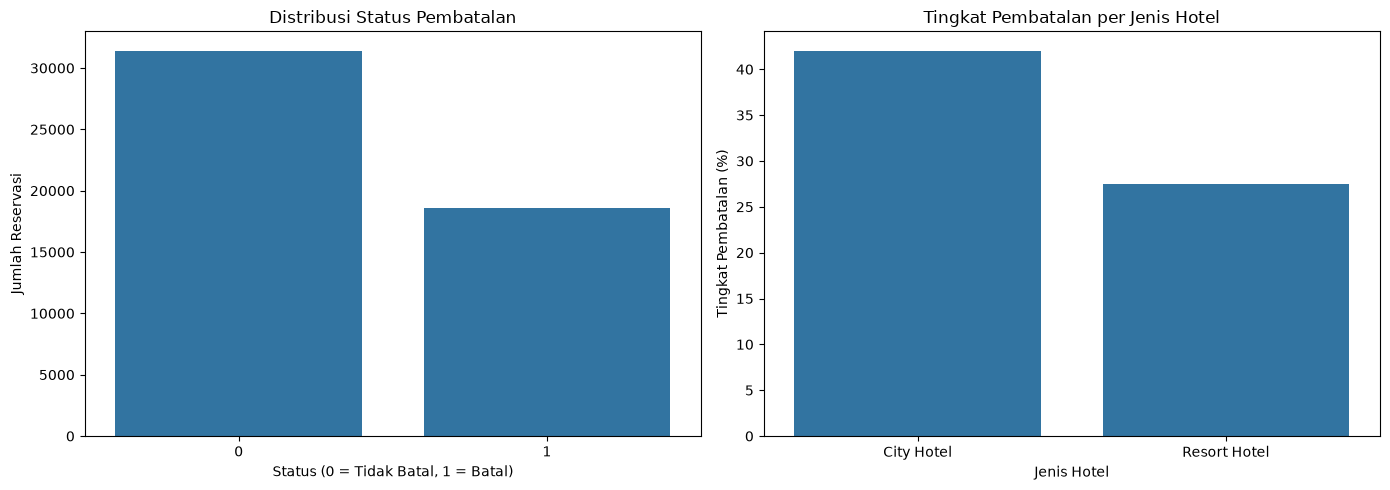

In [19]:
# Visualisasi distribusi status pembatalan reservasi dan tingkat pembatalan per jenis hotel
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=df_hotel, x="is_canceled", ax=ax[0])
ax[0].set_title("Distribusi Status Pembatalan")
ax[0].set_xlabel("Status (0 = Tidak Batal, 1 = Batal)")
ax[0].set_ylabel("Jumlah Reservasi")

hotel_rate = df_hotel.groupby("hotel")["is_canceled"].mean() * 100
sns.barplot(x=hotel_rate.index, y=hotel_rate.values, ax=ax[1])
ax[1].set_title("Tingkat Pembatalan per Jenis Hotel")
ax[1].set_xlabel("Jenis Hotel")
ax[1].set_ylabel("Tingkat Pembatalan (%)")

plt.tight_layout()
plt.show()

### Interpretasi Status Pembatalan dan Jenis Hotel

Dari 50.000 reservasi dalam sampel, 31.420 reservasi (62,84%) tidak dibatalkan dan 18.580 reservasi (37,16%) dibatalkan. Dengan demikian, kelas tidak dibatalkan lebih banyak daripada kelas dibatalkan. Berdasarkan jenis hotel, tingkat pembatalan City Hotel sekitar 42,0%, sedangkan Resort Hotel sekitar 27,5%. Perbedaan ini menunjukkan bahwa pola pembatalan tidak sama pada kedua jenis hotel, tetapi grafik ini tidak menjelaskan penyebab perbedaannya.

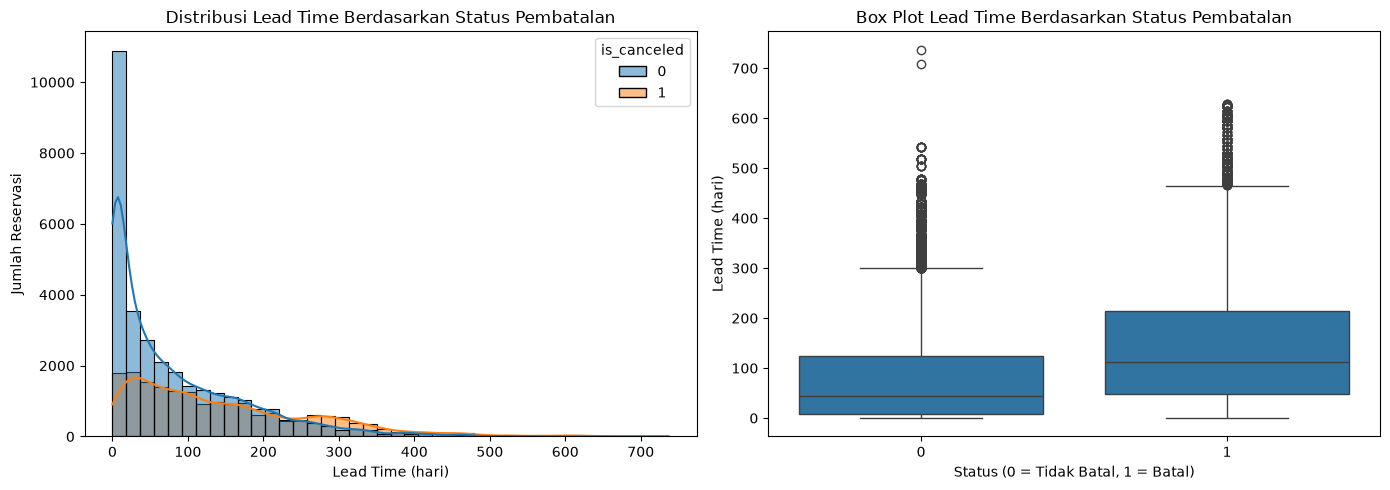

In [20]:
# Visualisasi lead time berdasarkan status pembatalan (histogram dan box plot)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df_hotel, x="lead_time", hue="is_canceled", kde=True, bins=40, stat="count", common_norm=False, ax=ax[0])
ax[0].set_title("Distribusi Lead Time Berdasarkan Status Pembatalan")
ax[0].set_xlabel("Lead Time (hari)")
ax[0].set_ylabel("Jumlah Reservasi")

sns.boxplot(data=df_hotel, x="is_canceled", y="lead_time", ax=ax[1])
ax[1].set_title("Box Plot Lead Time Berdasarkan Status Pembatalan")
ax[1].set_xlabel("Status (0 = Tidak Batal, 1 = Batal)")
ax[1].set_ylabel("Lead Time (hari)")

plt.tight_layout()
plt.show()

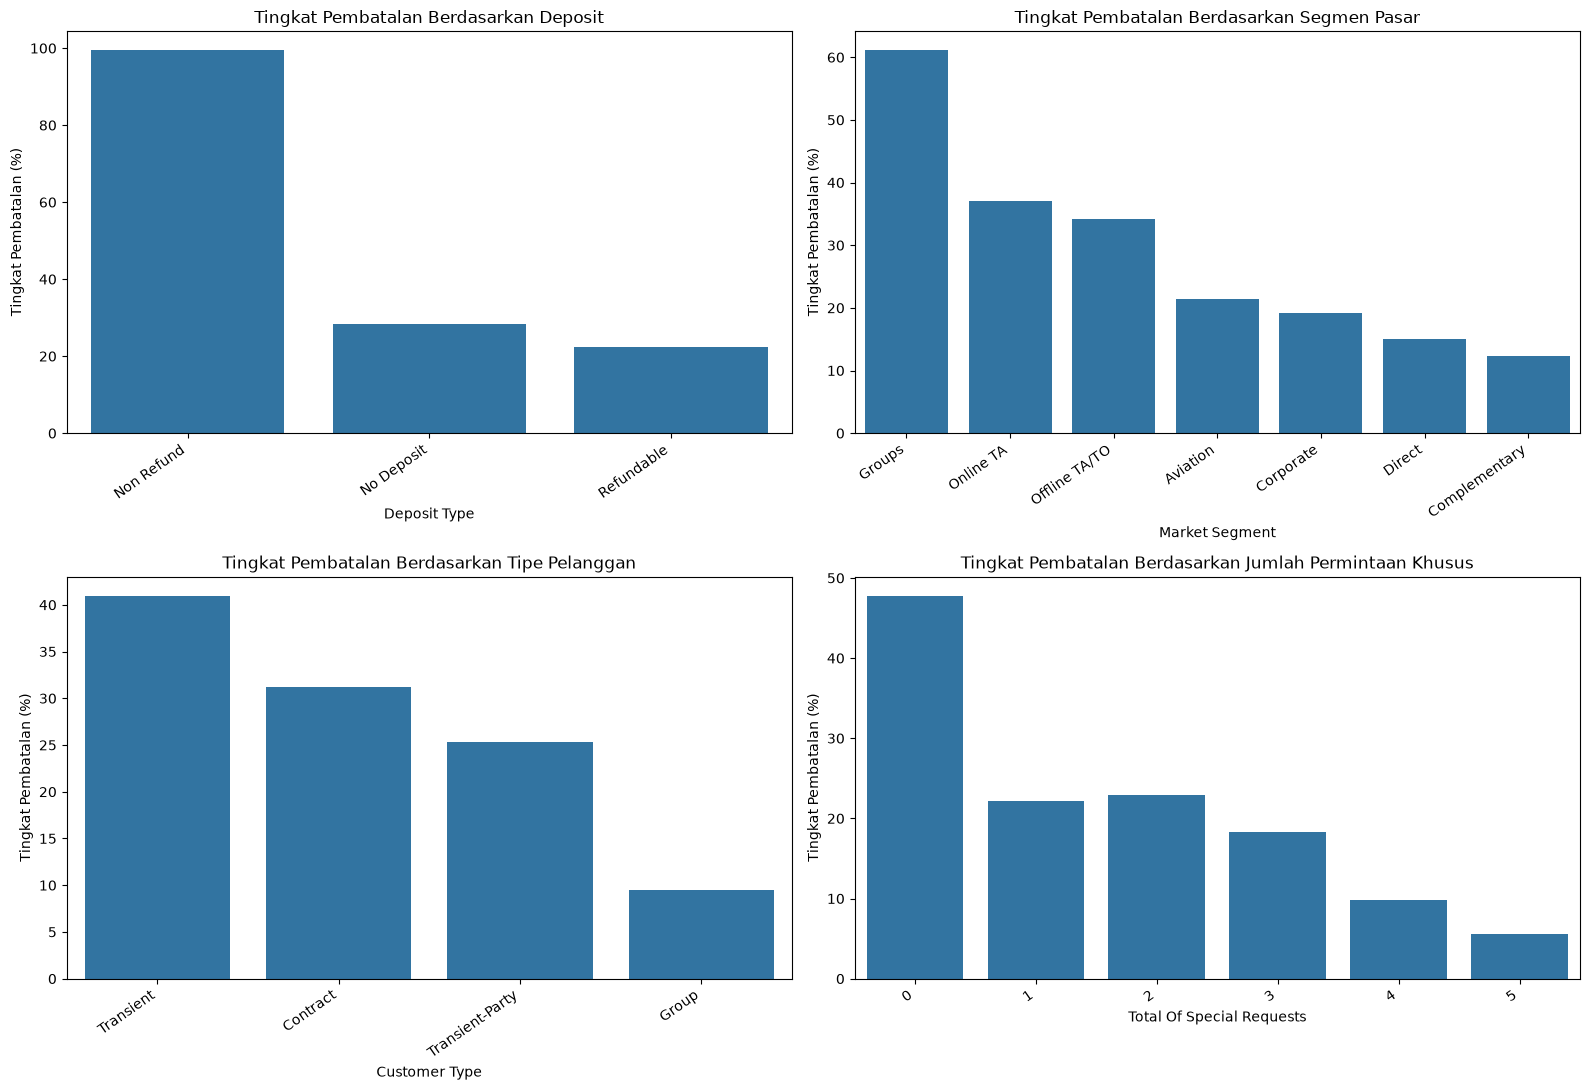

In [21]:

# Visualisasi tingkat pembatalan berdasarkan karakteristik reservasi:
# tipe deposit, segmen pasar, tipe pelanggan, dan jumlah permintaan khusus

kolom_perbandingan = [
    ("deposit_type", "Tingkat Pembatalan Berdasarkan Deposit"),
    ("market_segment", "Tingkat Pembatalan Berdasarkan Segmen Pasar"),
    ("customer_type", "Tingkat Pembatalan Berdasarkan Tipe Pelanggan"),
    ("total_of_special_requests", "Tingkat Pembatalan Berdasarkan Jumlah Permintaan Khusus")
]

fig, ax = plt.subplots(2, 2, figsize=(16, 11))
ax = ax.flatten()

for i, (kolom, judul) in enumerate(kolom_perbandingan):
    data_plot = (
        df_hotel.groupby(kolom, dropna=False)["is_canceled"].mean().mul(100)
        .reset_index(name="Tingkat Pembatalan (%)").sort_values(by="Tingkat Pembatalan (%)", ascending=False)
    )
    sns.barplot(data=data_plot, x=kolom, y="Tingkat Pembatalan (%)", ax=ax[i])
    ax[i].set_title(judul)
    ax[i].set_xlabel(kolom.replace("_", " ").title())
    ax[i].set_ylabel("Tingkat Pembatalan (%)")
    ax[i].tick_params(axis="x", rotation=35)
    for label in ax[i].get_xticklabels(): label.set_ha("right")

plt.tight_layout()
plt.show()


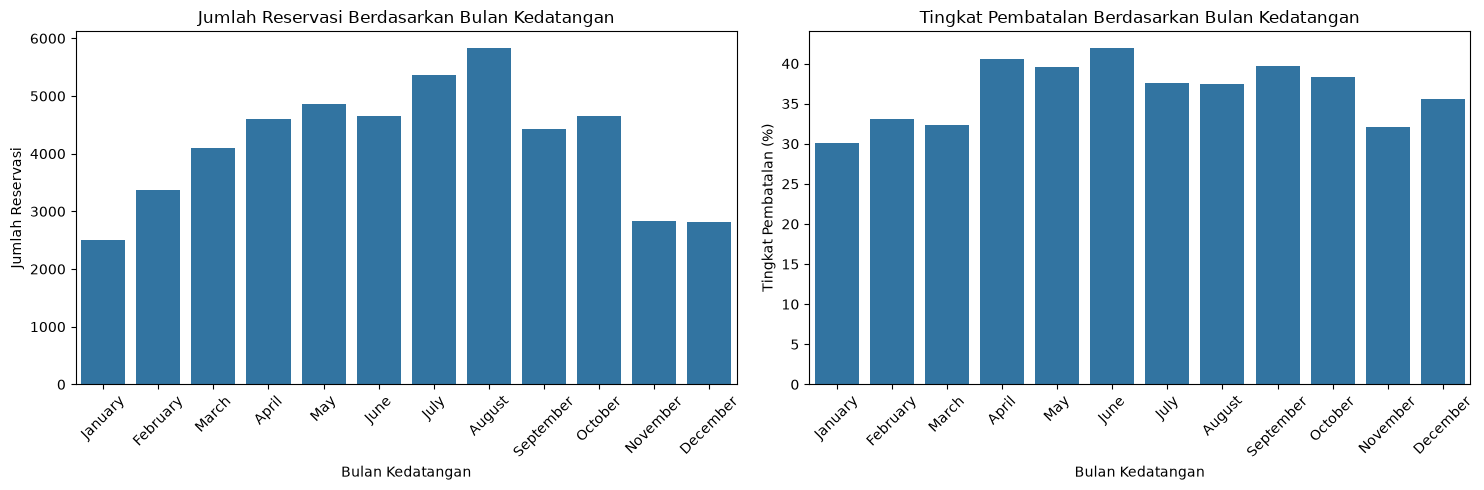

In [22]:
# Visualisasi tingkat pembatalan per bulan kedatangan berdasarkan jumlah reservasi dan tingkat pembatalan (%)
urutan_bulan = [
    "January", "February", "March", "April", "May", "June", "July", 
    "August", "September", "October", "November", "December"
]

df_bulan = (df_hotel.groupby("arrival_date_month").agg(
        Jumlah_Reservasi=("is_canceled", "size"),
        Jumlah_Dibatalkan=("is_canceled", "sum"),
        Tingkat_Pembatalan=("is_canceled", "mean")
    ).reindex(urutan_bulan).reset_index().rename(columns={"arrival_date_month": "Bulan"})
)

df_bulan["Tingkat_Pembatalan"] = (df_bulan["Tingkat_Pembatalan"] * 100)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(data=df_bulan, x="Bulan", y="Jumlah_Reservasi", ax=ax[0])
ax[0].set_title("Jumlah Reservasi Berdasarkan Bulan Kedatangan")
ax[0].set_xlabel("Bulan Kedatangan")
ax[0].set_ylabel("Jumlah Reservasi")
ax[0].tick_params(axis="x", rotation=45)

sns.barplot(data=df_bulan, x="Bulan", y="Tingkat_Pembatalan", ax=ax[1])
ax[1].set_title("Tingkat Pembatalan Berdasarkan Bulan Kedatangan")
ax[1].set_xlabel("Bulan Kedatangan")
ax[1].set_ylabel("Tingkat Pembatalan (%)")
ax[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


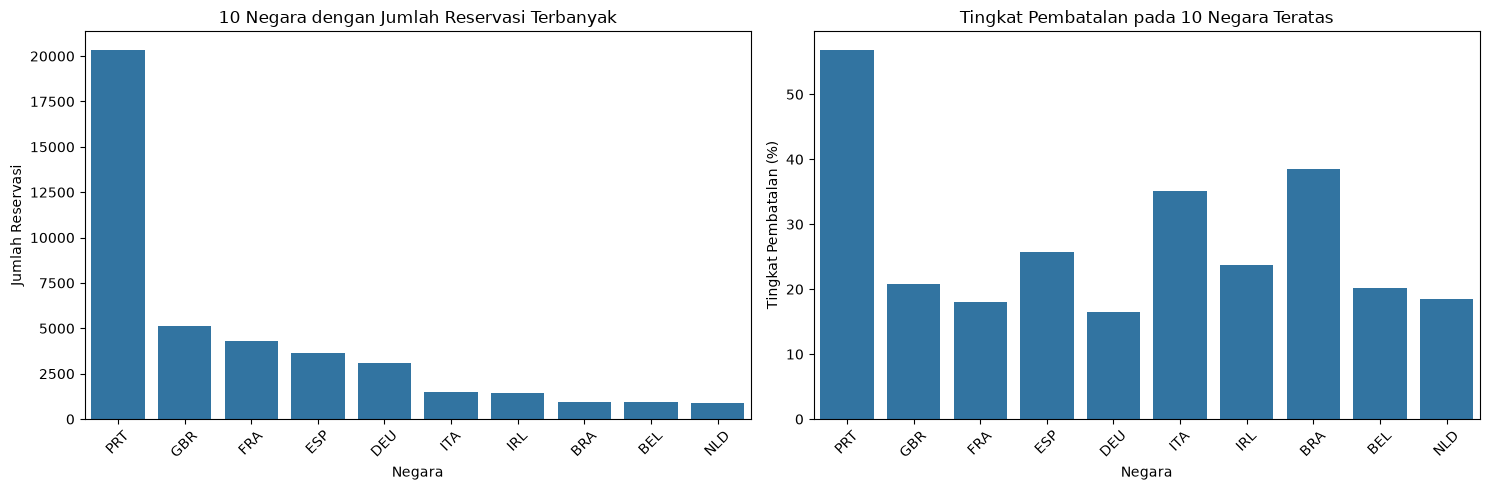

In [23]:
# Visualisasi tingkat pembatalan pada 10 negara dengan reservasi terbanyak
top_10_negara = (df_hotel["country"].value_counts().head(10).index)

df_negara = (df_hotel[df_hotel["country"].isin(top_10_negara)].groupby("country").agg(
        Jumlah_Reservasi=("is_canceled", "size"),
        Jumlah_Dibatalkan=("is_canceled", "sum"),
        Tingkat_Pembatalan=("is_canceled", "mean")
    ).sort_values("Jumlah_Reservasi", ascending=False).reset_index()
)

df_negara["Tingkat_Pembatalan"] = (df_negara["Tingkat_Pembatalan"] * 100)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(data=df_negara, x="country", y="Jumlah_Reservasi", ax=ax[0])
ax[0].set_title("10 Negara dengan Jumlah Reservasi Terbanyak")
ax[0].set_xlabel("Negara")
ax[0].set_ylabel("Jumlah Reservasi")
ax[0].tick_params(axis="x", rotation=45)

sns.barplot(data=df_negara, x="country", y="Tingkat_Pembatalan", ax=ax[1])
ax[1].set_title("Tingkat Pembatalan pada 10 Negara Teratas")
ax[1].set_xlabel("Negara")
ax[1].set_ylabel("Tingkat Pembatalan (%)")
ax[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


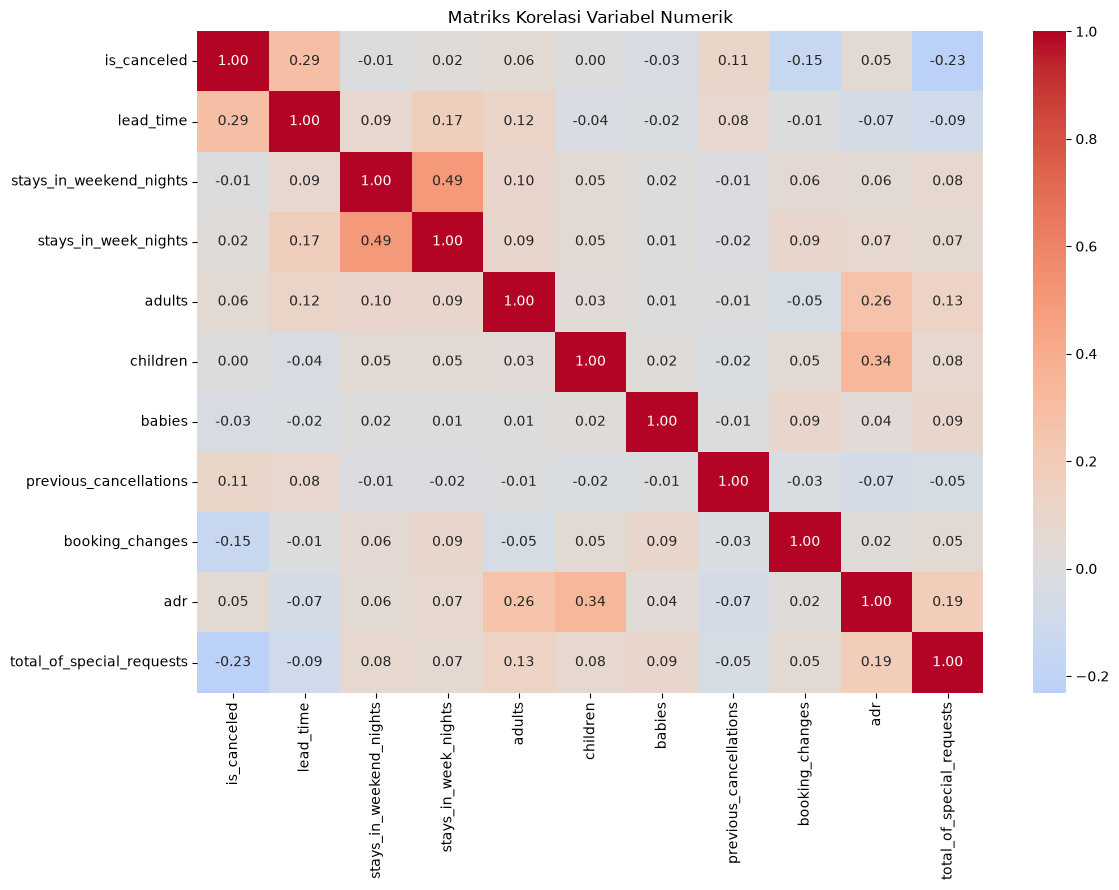

In [24]:
# Visualisasi korelasi antara variabel numerik
kolom_korelasi = [
    "is_canceled",
    "lead_time",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "previous_cancellations",
    "booking_changes",
    "adr",
    "total_of_special_requests"
]
matriks_korelasi = df_hotel[kolom_korelasi].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(matriks_korelasi, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriks Korelasi Variabel Numerik")
plt.tight_layout()
plt.show()

- Korelasi positif menunjukkan bahwa nilai variabel cenderung bergerak searah dengan nilai target.
- Korelasi negatif menunjukkan kecenderungan berlawanan arah.
- Nilai mendekati nol menunjukkan hubungan linear yang lemah, tetapi bukan berarti tidak ada hubungan dalam bentuk lain.

Korelasi tidak membuktikan sebab-akibat. Variabel yang tampak berhubungan dengan pembatalan juga perlu ditinjau dari sisi ketersediaannya pada waktu prediksi agar tidak terjadi data leakage.

### 2.5 Representative dan Potensi Bias Sample

In [25]:
# Membandingkan proporsi target pada dataset asli dan sampel
perbandingan_target = pd.DataFrame({
    "Dataset Asli (%)": df ["is_canceled"].value_counts(
        normalize=True).sort_index() * 100,
    "Dataset Sampel (%)": df_hotel["is_canceled"].value_counts(
        normalize=True).sort_index() * 100,
})
perbandingan_target.index.name = "is_canceled"
perbandingan_target.round(2)

,Dataset Asli (%),Dataset Sampel (%)
is_canceled,,
0,62.96,62.84
1,37.04,37.16


**Interpretasi Representativitas dan Potensi Bias Sampel**

Perbandingan antara dataset asli dan sampel dilakukan untuk memeriksa apakah pengambilan 50.000 baris mempertahankan karakteristik utama dataset. Perbandingan mencakup proporsi status pembatalan, jenis hotel, dan tahun kedatangan.

Jika proporsi pada dataset sampel mendekati dataset asli, sampel dapat dianggap cukup mewakili karakteristik yang dibandingkan. Namun, kemiripan pada ketiga aspek tersebut tidak menjamin seluruh karakteristik dataset terwakili secara sempurna.

Penggunaan sampel acak dengan `random_state=42` membantu reproduksibilitas, tetapi hasil analisis tetap perlu dipahami dalam konteks keterbatasan pengambilan sampel.

In [26]:
# Membandingkan proporsi jenis hotel pada dataset asli dan sampel
perbandingan_hotel = pd.DataFrame({
    "Dataset Asli (%)": (
        df["hotel"].value_counts(normalize=True) * 100
    ),
    "Sampel (%)": (
        df_hotel["hotel"].value_counts(normalize=True) * 100
    )
})

perbandingan_hotel.index.name = "Jenis Hotel"

display(perbandingan_hotel.round(2))

,Dataset Asli (%),Sampel (%)
Jenis Hotel,,
City Hotel,66.45,66.49
Resort Hotel,33.55,33.51


In [27]:
# Membandingkan proporsi tahun kedatangan
perbandingan_tahun = pd.DataFrame({
    "Dataset Asli (%)": (
        df["arrival_date_year"].value_counts(normalize=True) * 100
    ),
    "Sampel (%)": (
        df_hotel["arrival_date_year"].value_counts(normalize=True) * 100
    )
})

perbandingan_tahun.index.name = "Tahun Kedatangan"

display(perbandingan_tahun.sort_index().round(2))

,Dataset Asli (%),Sampel (%)
Tahun Kedatangan,,
2015,18.42,18.46
2016,47.50,47.36
2017,34.08,34.18


### 2.6 Ringkasan Temuan Data

In [28]:
# Ringkasan awal kualitas data
total_baris = len(df_hotel)
total_kolom = df_hotel.shape[1]

jumlah_missing = int(df_hotel.isnull().sum().sum())
jumlah_duplikat = int(df_hotel.duplicated().sum())

jumlah_batal = int((df_hotel["is_canceled"] == 1).sum())
jumlah_tidak_batal = int((df_hotel["is_canceled"] == 0).sum())

total_nights = (
    df_hotel["stays_in_weekend_nights"]
    + df_hotel["stays_in_week_nights"]
)

total_guests = (
    df_hotel["adults"].fillna(0)
    + df_hotel["children"].fillna(0)
    + df_hotel["babies"].fillna(0)
)

ringkasan_data = pd.DataFrame({
    "Indikator": [
        "Jumlah baris sampel",
        "Jumlah kolom sampel",
        "Total nilai kosong pada seluruh kolom",
        "Jumlah baris duplikat identik",
        "Reservasi dibatalkan",
        "Reservasi tidak dibatalkan",
        "Reservasi tanpa tamu berdasarkan pemeriksaan",
        "Reservasi dengan ADR negatif",
        "Reservasi dengan ADR nol",
        "Reservasi dengan lama menginap nol malam"
    ],
    "Hasil": [
        total_baris,
        total_kolom,
        jumlah_missing,
        jumlah_duplikat,
        jumlah_batal,
        jumlah_tidak_batal,
        int((total_guests == 0).sum()),
        int((df_hotel["adr"] < 0).sum()),
        int((df_hotel["adr"] == 0).sum()),
        int((total_nights == 0).sum())
    ]
})

display(ringkasan_data)

,Indikator,Hasil
0,Jumlah baris sampel,50000
1,Jumlah kolom sampel,32
2,Total nilai kosong pada seluruh kolom,54206
3,Jumlah baris duplikat identik,10735
4,Reservasi dibatalkan,18580
5,Reservasi tidak dibatalkan,31420
6,Reservasi tanpa tamu berdasarkan pemeriksaan,69
7,Reservasi dengan ADR negatif,1
8,Reservasi dengan ADR nol,780
9,Reservasi dengan lama menginap nol malam,298


**Ringkasan Temuan Data**

Berdasarkan Data Understanding dan EDA, dataset memiliki karakteristik reservasi yang dapat dianalisis untuk memahami pola pembatalan hotel. Pemeriksaan kualitas data juga digunakan untuk mengidentifikasi nilai kosong, duplikasi, serta nilai yang perlu ditinjau lebih lanjut.

Temuan dari tahap ini menjadi dasar untuk menentukan penanganan data pada tahap Data Preparation. Pembersihan dilakukan dengan mempertimbangkan kondisi data dan makna setiap variabel, sedangkan fitur yang berpotensi menimbulkan data leakage ditinjau sebelum digunakan dalam pemodelan.

## Data Preparation

### 3.1 Kondisi Awal Dataset

In [29]:
# Membuat salinan dataset sampel untuk data preparation
df_clean = df_hotel.copy(deep=True)
print("Ukuran dataset awal:", df_clean.shape)

Ukuran dataset awal: (50000, 32)


In [30]:
# Memastikan kondisi dataset setelah salinan dibuat
print("Total missing value df_hotel : ", df_hotel.isnull().sum().sum()) # dataset sampel asli
print("Total missing value df_clean : ", df_clean.isnull().sum().sum()) # dataset yang telah dibersihkan

print("Missing value df_clean per kolom:")
print(df_clean.isnull().sum().loc[lambda x: x > 0])

Total missing value df_hotel :  54206
Total missing value df_clean :  54206
Missing value df_clean per kolom:
country      209
agent       6842
company    47155
dtype: int64


Salinan df_clean digunakan agar data awal tidak berubah dan bisa dibandingkan dengan hasil akhir.

### 3.2 Periksa Kondisi Awal Dataset

In [31]:

# Menyimpan kondisi awal untuk evaluasi cleaning
kondisi_awal = {
    "Jumlah Baris": len(df_clean),
    "Jumlah Kolom": len(df_clean.columns),
    "Total Missing Value": int(df_clean.isnull().sum().sum()),
    "Total Baris Duplikat": int(df_clean.duplicated().sum())
}
display(pd.DataFrame(list(kondisi_awal.items()), columns=["Kondisi", "Sebelum Cleaning"]))

,Kondisi,Sebelum Cleaning
0,Jumlah Baris,50000
1,Jumlah Kolom,32
2,Total Missing Value,54206
3,Total Baris Duplikat,10735


### 3.3 Menangani Baris Duplikat

In [32]:
# Menghapus baris yang duplikat yang identik
baris_sebelum = len(df_clean)
duplikat_sebelum = int(df_clean.duplicated().sum())

# Tingkat pembatalan sebelum cleaning
pembatalan_sebelum = df_clean["is_canceled"].mean() * 100 

df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print("Jumlah baris sebelum cleaning:", baris_sebelum)
print("Jumlah duplikat yang dihapus:", duplikat_sebelum)
print("Jumlah baris sesudah cleaning:", len(df_clean))
print(f"Proporsi pembatalan sebelum: {pembatalan_sebelum:.2f}%")
print(f"Proporsi pembatalan sesudah: {df_clean['is_canceled'].mean() * 100:.2f}%")
print("Jumlah sisa baris duplikat:", df_clean.duplicated().sum())

Jumlah baris sebelum cleaning: 50000
Jumlah duplikat yang dihapus: 10735
Jumlah baris sesudah cleaning: 39265
Proporsi pembatalan sebelum: 37.16%
Proporsi pembatalan sesudah: 28.69%
Jumlah sisa baris duplikat: 0


In [33]:
# Memeriksa kondisi missing value pada dataset awal dan dataset cleaning
print("Total missing value pada df_hotel :", df_hotel.isnull().sum().sum())
print("Total missing value pada df_clean :", df_clean.isnull().sum().sum())

print("\nMissing value pada df_hotel per kolom:")
display(df_hotel.isnull().sum().loc[lambda x: x > 0].sort_values(ascending=False))

print("Missing value pada df_clean per kolom:")
display(df_clean.isnull().sum().loc[lambda x: x > 0].sort_values(ascending=False))

Total missing value pada df_hotel : 54206
Total missing value pada df_clean : 42553

Missing value pada df_hotel per kolom:


company    47155
agent       6842
country      209
dtype: int64

Missing value pada df_clean per kolom:


company    36908
agent       5450
country      195
dtype: int64

### 3.4 Menangani Missing Values

In [34]:
# Menangani missing values berdasarkan kondisi kolom
missing_sebelum = df_clean.isnull().sum()

print("Missing values sebelum penanganan:")
display(missing_sebelum[missing_sebelum > 0].sort_values(ascending=False))

# Menghapus company karena lebih dari 80% nilainya kosong
if "company" in df_clean.columns:
    persentase_company = df_clean["company"].isnull().mean() * 100

    if persentase_company > 80:
        df_clean = df_clean.drop(columns=["company"])
        print(f"Kolom company dihapus ({persentase_company:.2f}% kosong)")

# Mengisi nilai kosong pada country
if "country" in df_clean.columns:
    df_clean["country"] = df_clean["country"].fillna("Unknown")

# Mengisi nilai kosong pada agent dengan penanda 0
if "agent" in df_clean.columns:
    df_clean["agent"] = df_clean["agent"].fillna(0)

# Mengisi children yang kosong dengan 0 (tidak ada anak tercatat)
if "children" in df_clean.columns:
    df_clean["children"] = df_clean["children"].fillna(0)

print("\nMissing values setelah penanganan:")
display(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

Missing values sebelum penanganan:


company    36908
agent       5450
country      195
dtype: int64

Kolom company dihapus (94.00% kosong)

Missing values setelah penanganan:


Series([], dtype: int64)

In [35]:
# Memeriksa kondisi dataset sumber dan hasil cleaning
print("df_hotel:")
print("Jumlah baris:", len(df_hotel))
print("Jumlah kolom:", len(df_hotel.columns))
print("Total missing value:", df_hotel.isnull().sum().sum())

print("\ndf_clean:")
print("Jumlah baris:", len(df_clean))
print("Jumlah kolom:", len(df_clean.columns))
print("Total missing value:", df_clean.isnull().sum().sum())
print("Jumlah duplikasi:", df_clean.duplicated().sum())


df_hotel:
Jumlah baris: 50000
Jumlah kolom: 32
Total missing value: 54206

df_clean:
Jumlah baris: 39265
Jumlah kolom: 31
Total missing value: 0
Jumlah duplikasi: 2


In [36]:
# Memeriksa jumlah baris duplikat pada sumber data
print("Duplikasi pada df_hotel:", df_hotel.duplicated().sum())

# Memeriksa jumlah baris duplikat pada data hasil cleaning
print("Duplikasi pada df_clean:", df_clean.duplicated().sum())

# Memeriksa jumlah baris sumber data
print("Baris df_hotel:", len(df_hotel))

Duplikasi pada df_hotel: 10735
Duplikasi pada df_clean: 2
Baris df_hotel: 50000


### 3.5 Memeriksa Nilai Tidak Wajar
Pemeriksaan dilakukan **sebelum** penghapusan agar kondisi awalnya tercatat.

In [37]:
total_nights = (
    df_clean["stays_in_weekend_nights"] +
    df_clean["stays_in_week_nights"]
)

total_guests = (
    df_clean["adults"].fillna(0) +
    df_clean["children"].fillna(0) +
    df_clean["babies"].fillna(0)
)

periksa_anomali = {
    "Reservasi tanpa tamu": int((total_guests == 0).sum()),
    "Adults > 10": int((df_clean["adults"] > 10).sum()),
    "ADR negatif": int((df_clean["adr"] < 0).sum()),
    "ADR nol": int((df_clean["adr"] == 0).sum()),
    "Durasi nol malam": int((total_nights == 0).sum()),
    "Durasi > 30 malam": int((total_nights > 30).sum())
}

display(pd.DataFrame(
    periksa_anomali.items(),
    columns=["Kondisi", "Jumlah Baris"]
))

,Kondisi,Jumlah Baris
0,Reservasi tanpa tamu,66
1,Adults > 10,2
2,ADR negatif,1
3,ADR nol,738
4,Durasi nol malam,277
5,Durasi > 30 malam,8


### 3.6 Menghapus Data dengan Kondisi Tidak Valid
Baris yang dihapus: (a) tanpa tamu sama sekali, (b) `adults` > 10 (kemungkinan salah catat), (c) ADR negatif, dan (d) lama menginap 0 malam, karena reservasi tanpa malam menginap bukan menginap yang wajar. ADR = 0 dan menginap > 30 malam **dipertahankan** karena masih bisa sah (mis. kamar komplimenter, menginap panjang).

In [38]:
baris_sebelum = len(df_clean)

total_nights = (
    df_clean["stays_in_weekend_nights"] +
    df_clean["stays_in_week_nights"]
)

total_guests = (
    df_clean["adults"] +
    df_clean["children"].fillna(0) +
    df_clean["babies"]
)

# Reservasi tanpa tamu dan ADR negatif ditinjau sebagai anomali
invalid = (total_guests == 0) | (df_clean["adults"] > 10) | (df_clean["adr"] < 0) | (total_nights == 0)

print(f"Tingkat pembatalan pada baris yang akan dihapus: {df_clean.loc[invalid, 'is_canceled'].mean() * 100:.2f}%")
df_clean = df_clean[~invalid].reset_index(drop=True)

print(f"Jumlah baris sebelum dihapus : {baris_sebelum}")
print(f"Jumlah baris setelah dihapus : {len(df_clean)}")
print(f"Total baris yang dihapus     : {baris_sebelum - len(df_clean)}")

# Memeriksa ulang kondisi dataset
print("\nPemeriksaan ulang kondisi dataset setelah cleaning:")
total_nights = df_clean["stays_in_weekend_nights"] + df_clean["stays_in_week_nights"]
total_guests = df_clean["adults"] + df_clean["children"].fillna(0) + df_clean["babies"]

print("Reservasi tanpa tamu :", (total_guests == 0).sum())
print("Reservasi adults > 10:", (df_clean["adults"] > 10).sum())
print("Reservasi ADR negatif:", (df_clean["adr"] < 0).sum())
print("Reservasi 0 malam    :", (total_nights == 0).sum())

Tingkat pembatalan pada baris yang akan dihapus: 6.17%
Jumlah baris sebelum dihapus : 39265
Jumlah baris setelah dihapus : 38941
Total baris yang dihapus     : 324

Pemeriksaan ulang kondisi dataset setelah cleaning:
Reservasi tanpa tamu : 0
Reservasi adults > 10: 0
Reservasi ADR negatif: 0
Reservasi 0 malam    : 0


### 3.7 Memeriksa Kandidat Outlier setelah Cleaning

In [39]:
kolom_iqr = [
    "lead_time",
    "adr",
    "adults",
    "children",
    "babies",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "days_in_waiting_list"
]

hasil_iqr_bersih = []

for kolom in kolom_iqr:
    data = df_clean[kolom].dropna()

    q1 = data.quantile(0.25)
    q3 = data.quantile(0.75)
    iqr = q3 - q1

    batas_bawah = q1 - 1.5 * iqr
    batas_atas = q3 + 1.5 * iqr

    kandidat = (data < batas_bawah) | (data > batas_atas)

    hasil_iqr_bersih.append({
        "Kolom": kolom,
        "Batas Bawah": batas_bawah,
        "Batas Atas": batas_atas,
        "Jumlah Kandidat Outlier": int(kandidat.sum()),
        "Persentase (%)": kandidat.mean() * 100
    })

display(pd.DataFrame(hasil_iqr_bersih).round(2))

,Kolom,Batas Bawah,Batas Atas,Jumlah Kandidat Outlier,Persentase (%)
0,lead_time,-166.50,309.50,1053,2.70
1,adr,-18.73,223.88,1130,2.90
2,adults,2.00,2.00,10087,25.90
3,children,0.00,0.00,3481,8.94
4,babies,0.00,0.00,381,0.98
5,stays_in_weekend_nights,-3.00,5.00,83,0.21
6,stays_in_week_nights,-2.00,6.00,1351,3.47
7,days_in_waiting_list,0.00,0.00,491,1.26


### 3.8 Validasi Kondisi dan Tipe Data

In [40]:
# Membandingkan kondisi awal dan kondisi setelah cleaning
kondisi_akhir = {
    "Jumlah Baris": len(df_clean),
    "Jumlah Kolom": df_clean.shape[1],
    "Total Missing Value": int(df_clean.isnull().sum().sum()),
    "Jumlah Baris Duplikat": int(df_clean.duplicated().sum())
}

perbandingan_kondisi = pd.DataFrame(
    [kondisi_awal, kondisi_akhir],
    index=["Sebelum Cleaning", "Sesudah Cleaning"]
)

display(perbandingan_kondisi)

# Validasi tipe data setelah cleaning
df_clean.info()

,Jumlah Baris,Jumlah Kolom,Total Missing Value,Total Baris Duplikat,Jumlah Baris Duplikat
Sebelum Cleaning,50000,32,54206,10735.0,NaN
Sesudah Cleaning,38941,31,0,NaN,2.0


<class 'pandas.DataFrame'>
RangeIndex: 38941 entries, 0 to 38940
Data columns (total 31 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   hotel                           38941 non-null  str    
 1   is_canceled                     38941 non-null  int64  
 2   lead_time                       38941 non-null  int64  
 3   arrival_date_year               38941 non-null  int64  
 4   arrival_date_month              38941 non-null  str    
 5   arrival_date_week_number        38941 non-null  int64  
 6   arrival_date_day_of_month       38941 non-null  int64  
 7   stays_in_weekend_nights         38941 non-null  int64  
 8   stays_in_week_nights            38941 non-null  int64  
 9   adults                          38941 non-null  int64  
 10  children                        38941 non-null  float64
 11  babies                          38941 non-null  int64  
 12  meal                            38941 non-n

### 3.9 Feature Selection: Pencegahan Data Leakage

Feature selection dilakukan untuk memilih fitur yang relevan sebelum proses pemodelan. Pada proyek ini, prediksi pembatalan reservasi diasumsikan dilakukan saat reservasi pertama kali dibuat. Kolom yang dihapus: `reservation_status`, `reservation_status_date`, `booking_changes`, dan `assigned_room_type` dihapus karena berpotensi mengandung informasi yang belum tersedia pada waktu prediksi.

In [41]:
# Target prediksi
target = "is_canceled"

# Kolom yang berisiko membocorkan hasil akhir reservasi
kolom_leakage = [
    "reservation_status", "reservation_status_date", 
    "booking_changes", "assigned_room_type"
]
# Menghapus hanya kolom yang tersedia di dataset
kolom_dihapus = [
    kolom for kolom in kolom_leakage 
    if kolom in df_clean.columns
]
df_clean = df_clean.drop(columns=kolom_dihapus)

# Validasi hasil feature selection
print("Kolom yang dihapus:", kolom_dihapus)
print("Target tersedia:", target in df_clean.columns)
print("Ukuran dataset:", df_clean.shape)
print("Total missing values:", df_clean.isnull().sum().sum())

print("\nKolom yang masih perlu ditinjau:")
print(df_clean.columns.tolist())
display(df_clean.head())

Kolom yang dihapus: ['reservation_status', 'reservation_status_date', 'booking_changes', 'assigned_room_type']
Target tersedia: True
Ukuran dataset: (38941, 27)
Total missing values: 0

Kolom yang masih perlu ditinjau:
['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'deposit_type', 'agent', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,deposit_type,agent,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests
0,Resort Hotel,0,203,2016,December,49,2,2,5,2,...,0,0,F,No Deposit,250.0,0,Transient,66.8,0,0
1,City Hotel,1,82,2015,July,29,16,0,3,2,...,0,0,A,No Deposit,9.0,0,Transient,76.5,0,0
2,City Hotel,0,25,2016,December,53,27,0,3,3,...,0,0,A,No Deposit,220.0,0,Transient-Party,60.0,0,1
3,City Hotel,0,1,2016,March,11,9,0,1,1,...,0,0,A,No Deposit,9.0,0,Transient-Party,95.0,0,0
4,City Hotel,0,70,2017,April,16,16,2,2,2,...,0,0,A,No Deposit,9.0,0,Transient,108.0,0,0


### 3.10 Menyimpan Dataset Hasil Data Preparation

In [42]:
# Ekspor data yang sudah dibersihkan
df_clean.to_csv("hotel_bookings_clean.csv", index=False)

print("Dataset berhasil disimpan sebagai hotel_bookings_clean.csv")
print("Ukuran akhir dataset:", df_clean.shape)

Dataset berhasil disimpan sebagai hotel_bookings_clean.csv
Ukuran akhir dataset: (38941, 27)


### 3.11 Ringkasan Tingkat Pembatalan pada Data Bersih

In [43]:
# Tingkat pembatalan (%) pada data bersih untuk beberapa faktor utama
df_summary = df_clean.copy()
df_summary["lead_time_category"] = pd.cut(df_summary["lead_time"], bins=[-1, 30, 90, 180, df_summary["lead_time"].max()],
                                          labels=["<= 30 hari", "31 - 90 hari", "91 - 180 hari", "> 180 hari"])

for col in ["hotel", "deposit_type", "market_segment", "customer_type", "total_of_special_requests", "lead_time_category"]:
    rate = (df_summary.groupby(col, observed=True)["is_canceled"].mean() * 100).round(1)
    print(f"--- {col}")
    print(rate.to_string(), "\n")

print("Baris yang identik pada seluruh fitur yang dipakai:", df_clean.duplicated().sum())

--- hotel
hotel
City Hotel      31.7
Resort Hotel    24.2 

--- deposit_type
deposit_type
No Deposit    27.4
Non Refund    96.7
Refundable    24.3 

--- market_segment
market_segment
Aviation         21.5
Complementary    11.7
Corporate        13.1
Direct           14.9
Groups           34.1
Offline TA/TO    17.1
Online TA        36.4 

--- customer_type
customer_type
Contract           18.4
Group               8.6
Transient          31.7
Transient-Party    17.4 

--- total_of_special_requests
total_of_special_requests
0    35.1
1    22.8
2    22.7
3    17.6
4    10.1
5     5.6 

--- lead_time_category
lead_time_category
<= 30 hari       17.0
31 - 90 hari     32.7
91 - 180 hari    36.2
> 180 hari       42.6 

Baris yang identik pada seluruh fitur yang dipakai: 774
